In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

**phase 1 step 5**

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
from tensorflow.keras.applications import MobileNetV2
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


**phase 2**

In [ ]:
 import os;  print(os.listdir('/kaggle/input/datasets/')) 

In [ ]:
import os
[print(root) for root, dirs, files in os.walk('/kaggle/input/') if 'Parasitized' in dirs or 'Uninfected' in dirs]

**phase 2 step 1**

In [3]:
import os
base_dir = '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images'
for folder in os.listdir(base_dir):
    path = os.path.join(base_dir, folder)
    count = len(os.listdir(path))
    print(f"{folder}: {count} images")

Uninfected: 13780 images
Parasitized: 13780 images


In [4]:
import os
base_dir = '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images'
valid_ext = (".png", ".jpg", ".jpeg")
for folder in os.listdir(base_dir):
    path = os.path.join(base_dir, folder)
    count = len([f for f in os.listdir(path) if f.lower().endswith(valid_ext)])
    print(f"{folder}: {count} images")

Uninfected: 13779 images
Parasitized: 13779 images


In [3]:
for c in os.listdir(base_dir):
    p = os.path.join(base_dir, c)
    print(c, [f for f in os.listdir(p) if not f.lower().endswith((".png", ".jpg", ".jpeg"))])

Parasitized ['Thumbs.db']
Uninfected ['Thumbs.db']


In [3]:
for folder in os.listdir(base_dir):
    path = os.path.join(base_dir, folder)
    print(f"{folder}: {len([f for f in os.listdir(path) if f.lower().endswith('.png')])} images")

Parasitized: 13779 images
Uninfected: 13779 images


**phase 2 step 2**

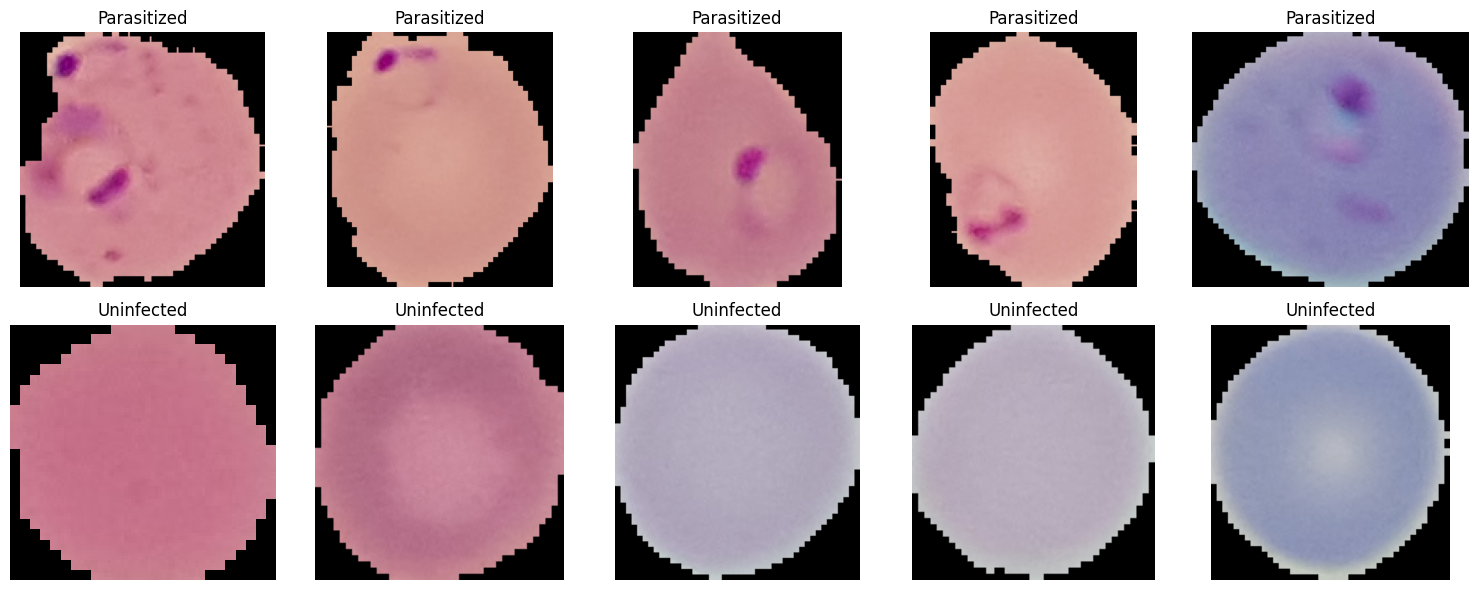

In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, category in enumerate(['Parasitized', 'Uninfected']):
    folder = os.path.join(base_dir, category)
    images = random.sample(os.listdir(folder), 5)
    for j, img_name in enumerate(images):
        img = mpimg.imread(os.path.join(folder, img_name))
        axes[i][j].imshow(img)
        axes[i][j].set_title(category)
        axes[i][j].axis('off')
plt.tight_layout()
plt.show()

**step 3**

In [6]:
!pip install split-folders -q
import splitfolders

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

# Physically split into train/val/test folders (80/10/10) — done ONCE
splitfolders.ratio(
    base_dir,
    output="/kaggle/working/split_data",
    seed=SEED,
    ratio=(.8, .1, .1)
)

train_dir = "/kaggle/working/split_data/train"
val_dir   = "/kaggle/working/split_data/val"
test_dir  = "/kaggle/working/split_data/test"

# Confirm the split worked
for split in ["train", "val", "test"]:
    for cls in ["Parasitized", "Uninfected"]:
        p = os.path.join("/kaggle/working/split_data", split, cls)
        print(split, cls, len(os.listdir(p)))


Copying files: 27560 files [04:22, 105.05 files/s]

train Parasitized 11024
train Uninfected 11024
val Parasitized 1378
val Uninfected 1378
test Parasitized 1378
test Uninfected 1378


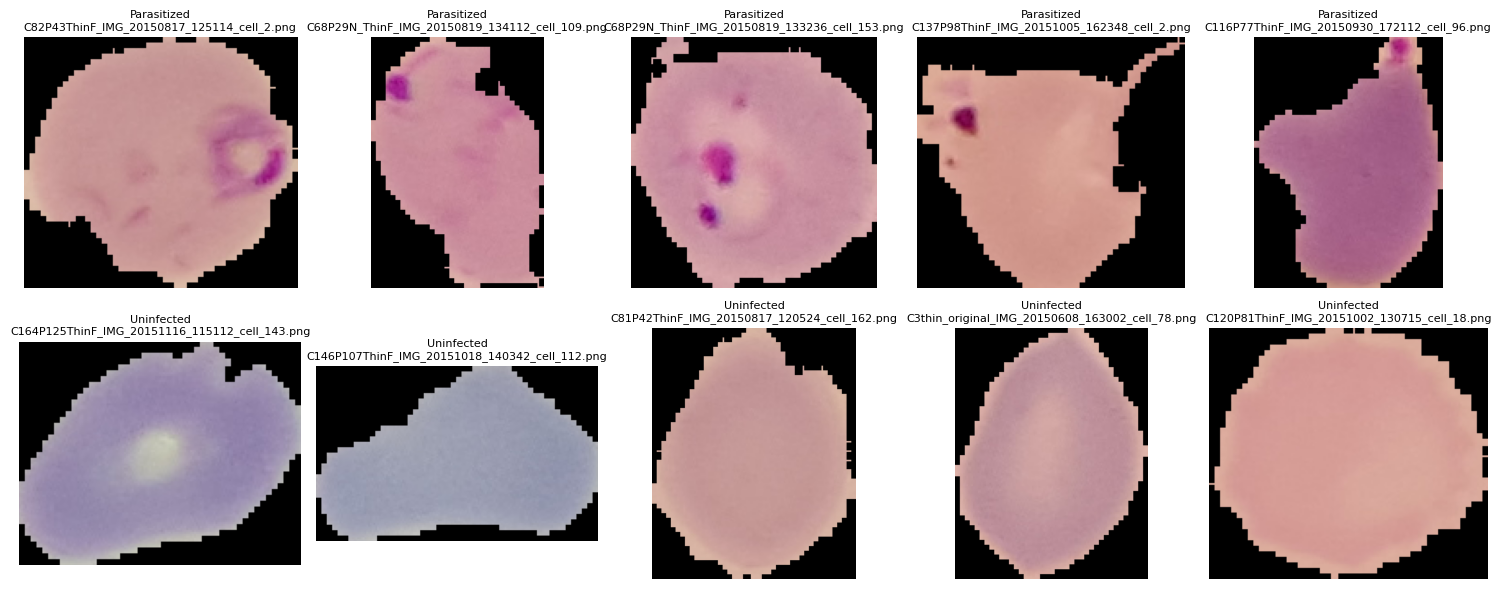

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os, random

test_dir = "/kaggle/working/split_data/test"

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, category in enumerate(['Parasitized', 'Uninfected']):
    folder = os.path.join(test_dir, category)
    images = random.sample(os.listdir(folder), 5)
    for j, img_name in enumerate(images):
        img = mpimg.imread(os.path.join(folder, img_name))
        axes[i][j].imshow(img)
        axes[i][j].set_title(f"{category}\n{img_name}", fontsize=8)
        axes[i][j].axis('off')

plt.tight_layout()
plt.show()

**step 4**

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Training generator — WITH augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2]
)

# Validation and test generators — NO augmentation, only normalisation
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    val_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', seed=SEED
)

print("Training samples:", train_generator.samples)
print("Validation samples:", val_generator.samples)
print("Classes:", train_generator.class_indices)


Found 22046 images belonging to 2 classes.
Found 2756 images belonging to 2 classes.
Training samples: 22046
Validation samples: 2756
Classes: {'Parasitized': 0, 'Uninfected': 1}


**step 5**

In [8]:
images, labels = next(train_generator)
print("Batch shape:", images.shape)        # should be (32, 224, 224, 3)
print("Label range:", labels.min(), labels.max())  # should be 0.0 and 1.0
print("Pixel range:", images.min(), images.max())  # should be 0.0 and 1.0

Batch shape: (32, 224, 224, 3)
Label range: 0.0 1.0
Pixel range: 0.0 1.0


**phase 3 step 1**

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, Model

# Load MobileNetV2 pretrained on ImageNet, without its top classification layer
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,        # remove ImageNet classification head
    weights='imagenet'        # use pretrained ImageNet weights
)

# Freeze all base model layers — we train only our new head first
base_model.trainable = False

print("Base model layers:", len(base_model.layers))
print("Trainable layers:", sum([l.trainable for l in base_model.layers]))

**phase 3 step 2**

In [ ]:
# Build the full model
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)     # compress feature maps
x = layers.Dense(128, activation='relu')(x) # learnable layer
x = layers.Dropout(0.3)(x)                 # prevent overfitting
outputs = layers.Dense(1, activation='sigmoid')(x)  # binary output

model = Model(inputs, outputs)
model.summary()

**phase 3 step 3**

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

# Callbacks — these automatically save your best model and stop early if needed
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '/kaggle/working/best_model_phase1.keras',
        save_best_only=True,
        monitor='val_accuracy',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,          # stop if no improvement for 5 epochs
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS_PHASE1 = 10

history_phase1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks,
    verbose=1
)

**phase 3 step 4**

In [ ]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'{title} — Accuracy')
    axes[0].legend()
    # Loss
    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title(f'{title} — Loss')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_phase1, "Phase 1: Feature Extraction")

**phase 3 step 5**

In [ ]:
# Unfreeze the last 30 layers of MobileNetV2
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with lower learning rate — critical for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # 100x smaller
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

callbacks_ft = [
    tf.keras.callbacks.ModelCheckpoint(
        '/kaggle/working/best_model_finetuned.keras',
        save_best_only=True,
        monitor='val_accuracy',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS_PHASE2 = 15

history_phase2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_PHASE2,
    callbacks=callbacks_ft,
    verbose=1
)

plot_history(history_phase2, "Phase 2: Fine-tuning")

**phase 3 step 6**

In [ ]:
model.save('/kaggle/working/malaria_mobilenetv2_final.keras')
print("Model saved.")

**this step for loading the model when starting new session**

In [9]:
import tensorflow as tf 
model = tf.keras.models.load_model('/kaggle/input/models/shaimamamoun/malaria-mobilenetv2-final/keras/default/1/malaria_mobilenetv2_final.keras')

I0000 00:00:1793874541.650564      57 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793874541.654196      57 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


**phase 4 reminder**

In [10]:
test_generator = test_datagen.flow_from_directory(
    test_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=False
)



Found 2756 images belonging to 2 classes.


**phase 4 step 1**

In [11]:
import numpy as np
y_pred_prob = model.predict(test_generator, verbose=1)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_generator.classes

2026-11-05 10:29:27.599754: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 10:29:27.747316: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 10:29:27.884650: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793874569.381720     155 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


85/87 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step

2026-11-05 10:29:41.958136: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 10:29:42.094545: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


87/87 ━━━━━━━━━━━━━━━━━━━━ 28s 164ms/step


**phase 4 step 2**

In [15]:
from sklearn.metrics import (classification_report, roc_auc_score,
                              roc_curve, confusion_matrix)

auc = roc_auc_score(y_true, y_pred_prob)
cm = confusion_matrix(y_true, y_pred)   

infected_found  = cm[0, 0]
infected_missed = cm[0, 1]
healthy_flagged = cm[1, 0]   
healthy_correct = cm[1, 1]

print("Infected cells found:", infected_found, "of", cm[0].sum())
print("Infected cells missed:", infected_missed)
print("Healthy cells wrongly flagged:", healthy_flagged)
print("Healthy cells correct:", healthy_correct, "of", cm[1].sum())
print()
print(f"Recall (Parasitized):    {infected_found / cm[0].sum():.4f}")
print(f"Precision (Parasitized): {infected_found / (infected_found + healthy_flagged):.4f}")
print(f"Recall (Uninfected):     {healthy_correct / cm[1].sum():.4f}")
print(f"Precision (Uninfected):  {healthy_correct / (healthy_correct + infected_missed):.4f}")
print(f"Accuracy: {(infected_found + healthy_correct) / cm.sum():.4f}")
print(f"AUC: {auc:.4f}")

Infected cells found: 1303 of 1378
Infected cells missed: 75
Healthy cells wrongly flagged: 30
Healthy cells correct: 1348 of 1378

Recall (Parasitized):    0.9456
Precision (Parasitized): 0.9775
Recall (Uninfected):     0.9782
Precision (Uninfected):  0.9473
Accuracy: 0.9619
AUC: 0.9919


In [18]:
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

cm = confusion_matrix(y_true, y_pred)   

rows = []
for idx, name in [(0, "Parasitized (infected)"), (1, "Uninfected (healthy)")]:
    rows.append({
        "Class": name,
        "Images tested": f"{cm[idx].sum():,}",
        "Correctly identified": f"{cm[idx, idx]:,}",
        "Recall": f"{recall_score(y_true, y_pred, pos_label=idx):.1%}",
        "Precision": f"{precision_score(y_true, y_pred, pos_label=idx):.1%}",
        "F1-score": f"{f1_score(y_true, y_pred, pos_label=idx):.1%}",
    })
table_classes = pd.DataFrame(rows).set_index("Class")

table_overall = pd.DataFrame(
    {"Result": [
        f"{accuracy_score(y_true, y_pred):.1%} ({cm.trace():,} of {cm.sum():,} images correct)",
        f"{auc:.3f}",
    ]},
    index=["Accuracy", "AUC"],
)
table_overall.index.name = "Overall measure"

display(table_classes)
display(table_overall)


,Images tested,Correctly identified,Recall,Precision,F1-score
Class,,,,,
Parasitized (infected),"1,378","1,303",94.6%,97.7%,96.1%
Uninfected (healthy),"1,378","1,348",97.8%,94.7%,96.3%


,Result
Overall measure,
Accuracy,"96.2% (2,651 of 2,756 images correct)"
AUC,0.992


In [ ]:
from sklearn.metrics import (classification_report, roc_auc_score,
                              roc_curve, confusion_matrix)

print(classification_report(y_true, y_pred,
      target_names=["Parasitized", "Uninfected"]))   # ← corrected order

auc = roc_auc_score(y_true, y_pred_prob)
print(f"AUC: {auc:.4f}")

**phase 4 step 3**

In [ ]:
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Parasitized", "Uninfected"],   # ← corrected order
    yticklabels=["Parasitized", "Uninfected"])   # ← corrected order
plt.title("Confusion Matrix — NIH Test Set")
plt.ylabel("True Label"); plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()


**phase 4 step 4**

In [ ]:
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}", color="#1F4E5C", linewidth=2)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — NIH Test Set")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

**phase 5 step 1**

In [ ]:
!pip install tf-keras-vis -q

**phase 5 step 2**

In [ ]:
last_conv_layer = None
for layer in reversed(model.layers):
    try:
        if len(layer.output_shape) == 4:
            last_conv_layer = layer.name
            break
    except AttributeError:
        continue
print("Last conv layer:", last_conv_layer)

**phase 5 step 3**

In [ ]:
from tensorflow.keras.preprocessing import image as keras_image
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt

def get_gradcam_heatmap(model, img_array, last_conv_layer_name):
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_heatmap(img_path, heatmap, alpha=0.4):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_arr = keras_image.img_to_array(img)
    jet_colors = plt.cm.jet(np.arange(256))[:, :3]
    jet_hm = keras_image.array_to_img(jet_colors[np.uint8(255 * heatmap)])
    jet_hm = jet_hm.resize((224, 224))
    jet_hm = keras_image.img_to_array(jet_hm)
    return keras_image.array_to_img(jet_hm * alpha + img_arr)

**phase 5 step 3b**

In [ ]:
import numpy as np
p_dir = os.path.join(base_dir, "Parasitized")
u_dir = os.path.join(base_dir, "Uninfected")
wrong_examples = []
for label_name, folder in [('Parasitized', p_dir), ('Uninfected', u_dir)]:
    for nm in os.listdir(folder)[:100]:  # check first 100 to save time
        img_path = os.path.join(folder, nm)
        img = keras_image.load_img(img_path, target_size=(224, 224))
        arr = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)
        pred = model.predict(arr, verbose=0)[0][0]
        pred_label = "Parasitized" if pred > 0.5 else "Uninfected"
        if pred_label != label_name:
            wrong_examples.append((img_path, label_name))
    if len(wrong_examples) >= 2:
        break
print("Found", len(wrong_examples), "misclassified examples")
print(wrong_examples)


**phase 5 step 4**

In [ ]:
def show_gradcam(img_path, model, last_conv_layer, true_label):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_array = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)
    pred = model.predict(img_array, verbose=0)[0][0]
    pred_label = "Uninfected" if pred > 0.5 else "Parasitized"   # ← corrected
    confidence = pred if pred > 0.5 else 1 - pred
    heatmap = get_gradcam_heatmap(model, img_array, last_conv_layer)
    overlay = overlay_heatmap(img_path, heatmap)
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    axes[0].imshow(img); axes[0].set_title(f"Original\nTrue: {true_label}"); axes[0].axis("off")
    axes[1].imshow(heatmap, cmap="jet"); axes[1].set_title("Grad-CAM Heatmap"); axes[1].axis("off")
    axes[2].imshow(overlay); axes[2].set_title(f"Overlay\nPred: {pred_label} ({confidence:.1%})"); axes[2].axis("off")
    plt.tight_layout(); plt.show()


In [ ]:
p_dir = os.path.join(test_dir, "Parasitized")
u_dir = os.path.join(test_dir, "Uninfected")
print("Parasitized test images found:", len(os.listdir(p_dir)))
print("Uninfected test images found:", len(os.listdir(u_dir)))

for nm in os.listdir(p_dir)[:4]:
    show_gradcam(os.path.join(p_dir, nm), model, last_conv_layer, "Parasitized")
for nm in os.listdir(u_dir)[:4]:
    show_gradcam(os.path.join(u_dir, nm), model, last_conv_layer, "Uninfected")

**phase 5B**

In [ ]:
def get_gradcam_heatmap(model, img_array, last_conv_layer_name):
    base_model = model.get_layer(last_conv_layer_name)
    idx = model.layers.index(base_model)
    classifier_layers = model.layers[idx + 1:]

    with tf.GradientTape() as tape:
        conv_outputs = base_model(img_array, training=False)
        tape.watch(conv_outputs)
        x = conv_outputs
        for layer in classifier_layers:
            x = layer(x)
        class_channel = x[:, 0]

    grads = tape.gradient(class_channel, conv_outputs)[0]
    conv_outputs = conv_outputs[0]

    weights = tf.reduce_mean(grads, axis=(0, 1))
    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

In [ ]:
def compare_gradcam_methods(img_path, model, last_conv_layer, true_label):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_array = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)

    pred = model.predict(img_array, verbose=0)[0][0]
    pred_label = "Uninfected" if pred > 0.5 else "Parasitized"
    confidence = pred if pred > 0.5 else 1 - pred

    heatmap_v1 = get_gradcam_heatmap(model, img_array, last_conv_layer)
    heatmap_v2 = get_gradcam_pp_heatmap(model, img_array, last_conv_layer)

    overlay_v1 = overlay_heatmap(img_path, heatmap_v1)
    overlay_v2 = overlay_heatmap(img_path, heatmap_v2)

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    axes[0].imshow(img)
    axes[0].set_title(f"Original\nTrue: {true_label}")
    axes[0].axis("off")
    axes[1].imshow(overlay_v1)
    axes[1].set_title(f"Grad-CAM\nPred: {pred_label} ({confidence:.1%})")
    axes[1].axis("off")
    axes[2].imshow(overlay_v2)
    axes[2].set_title(f"Grad-CAM++\nPred: {pred_label} ({confidence:.1%})")
    axes[2].axis("off")
    axes[3].imshow(heatmap_v2, cmap="jet")
    axes[3].set_title("Grad-CAM++ Raw Heatmap")
    axes[3].axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
p_dir = os.path.join(test_dir, "Parasitized")
u_dir = os.path.join(test_dir, "Uninfected")

for nm in os.listdir(p_dir)[:4]:
    compare_gradcam_methods(os.path.join(p_dir, nm), model, last_conv_layer, "Parasitized")

for nm in os.listdir(u_dir)[:4]:
    compare_gradcam_methods(os.path.join(u_dir, nm), model, last_conv_layer, "Uninfected")


if 'wrong_examples' in dir() and len(wrong_examples) > 0:
    compare_gradcam_methods(wrong_examples[0][0], model, last_conv_layer, wrong_examples[0][1])

**PHASE 5 (corrected) + 5B: Grad-CAM and Grad-CAM++**

**Step 3a: Grad-CAM functions**


In [ ]:
def overlay_heatmap(img_path, heatmap, alpha=0.4):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_arr = keras_image.img_to_array(img)
    jet_colors = plt.cm.jet(np.arange(256))[:, :3]
    jet_hm = keras_image.array_to_img(jet_colors[np.uint8(255 * heatmap)])
    jet_hm = jet_hm.resize((224, 224))
    jet_hm = keras_image.img_to_array(jet_hm)
    return keras_image.array_to_img(jet_hm * alpha + img_arr)

In [ ]:
def get_gradcam_heatmap(model, img_array, last_conv_layer_name):
    base_model = model.get_layer(last_conv_layer_name)
    idx = model.layers.index(base_model)
    classifier_layers = model.layers[idx + 1:]

    with tf.GradientTape() as tape:
        conv_outputs = base_model(img_array, training=False)
        tape.watch(conv_outputs)
        x = conv_outputs
        for layer in classifier_layers[:-1]:
            x = layer(x)
        final_layer = classifier_layers[-1]
        logit = tf.matmul(x, final_layer.kernel) + final_layer.bias
        prob = tf.sigmoid(logit)
        class_channel = tf.where(prob[:, 0] > 0.5, logit[:, 0], -logit[:, 0])

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

**Step 3B: Grad-CAM++**

In [ ]:
def get_gradcam_pp_heatmap(model, img_array, last_conv_layer_name):
    base_model = model.get_layer(last_conv_layer_name)
    idx = model.layers.index(base_model)
    classifier_layers = model.layers[idx + 1:]

    with tf.GradientTape() as tape:
        conv_outputs = base_model(img_array, training=False)
        tape.watch(conv_outputs)
        x = conv_outputs
        for layer in classifier_layers[:-1]:
            x = layer(x)
        final_layer = classifier_layers[-1]
        logit = tf.matmul(x, final_layer.kernel) + final_layer.bias
        prob = tf.sigmoid(logit)
        class_channel = tf.where(prob[:, 0] > 0.5, logit[:, 0], -logit[:, 0])

    grads = tape.gradient(class_channel, conv_outputs)[0]
    conv_outputs = conv_outputs[0]

    grads_power_2 = grads ** 2
    grads_power_3 = grads ** 3
    global_sum = tf.reduce_sum(conv_outputs, axis=(0, 1))

    alpha_denom = grads_power_2 * 2.0 + global_sum * grads_power_3
    alpha_denom = tf.where(alpha_denom != 0.0, alpha_denom, tf.ones_like(alpha_denom))
    alphas = grads_power_2 / alpha_denom
    alphas_norm = alphas / (tf.reduce_sum(alphas, axis=(0, 1)) + 1e-8)

    weights = tf.reduce_sum(tf.nn.relu(grads) * alphas_norm, axis=(0, 1))

    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

**Step 4: Side-by-side comparison function**

In [ ]:
def compare_gradcam_methods(img_path, model, last_conv_layer, true_label):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_array = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)

    pred = model.predict(img_array, verbose=0)[0][0]
    pred_label = "Uninfected" if pred > 0.5 else "Parasitized"
    confidence = pred if pred > 0.5 else 1 - pred

    heatmap_v1 = get_gradcam_heatmap(model, img_array, last_conv_layer)
    heatmap_v2 = get_gradcam_pp_heatmap(model, img_array, last_conv_layer)
    overlay_v1 = overlay_heatmap(img_path, heatmap_v1)
    overlay_v2 = overlay_heatmap(img_path, heatmap_v2)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img)
    axes[0].set_title(f"Original\nTrue: {true_label}")
    axes[0].axis("off")
    axes[1].imshow(overlay_v1)
    axes[1].set_title(f"Grad-CAM\nPred: {pred_label} ({confidence:.1%})")
    axes[1].axis("off")
    axes[2].imshow(overlay_v2)
    axes[2].set_title(f"Grad-CAM++\nPred: {pred_label} ({confidence:.1%})")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()

**Step 5: Find misclassified test images** 

In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image as keras_image

In [ ]:
p_dir = os.path.join(test_dir, "Parasitized")
u_dir = os.path.join(test_dir, "Uninfected")

wrong_examples = []
for label_name, folder in [("Parasitized", p_dir), ("Uninfected", u_dir)]:
    found = 0
    for nm in os.listdir(folder)[:300]:
        img_path = os.path.join(folder, nm)
        img = keras_image.load_img(img_path, target_size=(224, 224))
        arr = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)
        pred = model.predict(arr, verbose=0)[0][0]
        pred_label = "Uninfected" if pred > 0.5 else "Parasitized"
        if pred_label != label_name:
            wrong_examples.append((img_path, label_name))
            found += 1
            if found >= 2:
                break

print("Found", len(wrong_examples), "misclassified examples")
print(wrong_examples)

**Step 6: Run the comparison**

In [ ]:
for nm in os.listdir(p_dir)[:4]:
    compare_gradcam_methods(os.path.join(p_dir, nm), model, last_conv_layer, "Parasitized")

for nm in os.listdir(u_dir)[:4]:
    compare_gradcam_methods(os.path.join(u_dir, nm), model, last_conv_layer, "Uninfected")

for img_path, true_label in wrong_examples[:2]:
    compare_gradcam_methods(img_path, model, last_conv_layer, true_label)